# Exercise 36 – Basin hopping and periodic boundary conditions

**Week 7 · Global optimisation and periodic systems**

1. **Basin hopping** (`scipy.optimize.basinhopping`) alternates random jumps
   with local minimisation and accepts/rejects the new minimum with a
   Metropolis criterion. It is an efficient global optimiser for clusters.
2. **Periodic boundary conditions** describe an infinite system by a unit
   cell that is repeated in all directions. Distances use the *minimum-image
   convention*: each atom interacts with the closest periodic copy of every
   other atom.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import basinhopping, minimize

from comphy.atoms import Cluster, LennardJones, random_positions

rng = np.random.default_rng(0)
calc = LennardJones()          # ε = 5, minimum at r = 1

## Basin hopping for a 12-atom Lennard-Jones cluster

local minimisation : E = -122.470
basin hopping      : E = -127.834


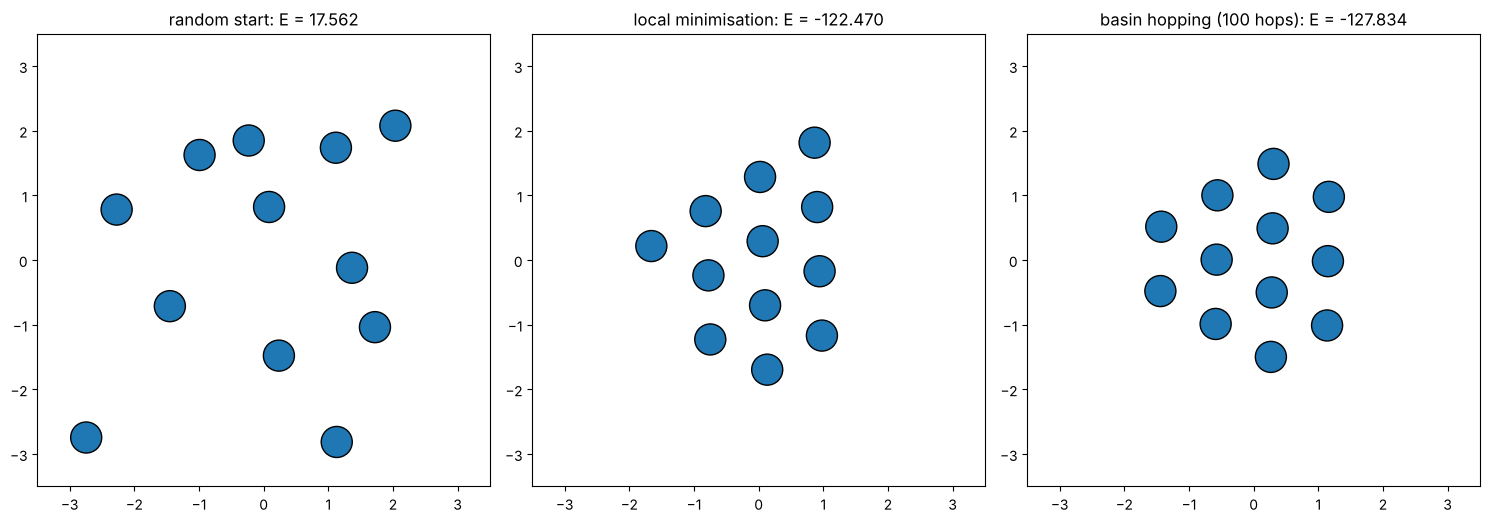

In [2]:
def energy_and_gradient(flat):
    pos = flat.reshape(-1, 2)
    return calc.energy(pos), -calc.forces(pos).ravel()


start = random_positions(12, box_half_width=2.5, min_distance=0.7, rng=rng)

local = minimize(energy_and_gradient, start.ravel(), jac=True, method="L-BFGS-B")
result = basinhopping(energy_and_gradient, start.ravel(), niter=100, seed=1,
                      minimizer_kwargs=dict(jac=True, method="L-BFGS-B"))
print(f"local minimisation : E = {local.fun:.3f}")
print(f"basin hopping      : E = {result.fun:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, pos, title in [(axes[0], start, "random start"),
                       (axes[1], local.x.reshape(-1, 2), "local minimisation"),
                       (axes[2], result.x.reshape(-1, 2), "basin hopping (100 hops)")]:
    pos = pos - pos.mean(axis=0)
    Cluster(calc, pos).draw(ax, size=500)
    ax.set(xlim=(-3.5, 3.5), ylim=(-3.5, 3.5))
    ax.set_title(f"{title}: {ax.get_title()}")
fig.tight_layout()
plt.show()

Basin hopping finds the compact, triangular-lattice cluster with the most
nearest-neighbour bonds; a single local minimisation stops in the nearest
(higher) minimum.

## Periodic boundary conditions
The same type of interaction in a periodic $10\times10$ cell. Shifting all
atoms by $(-3, 0)$ moves some of them out of the cell and they re-enter from
the other side – with the minimum-image convention the energy is unchanged.

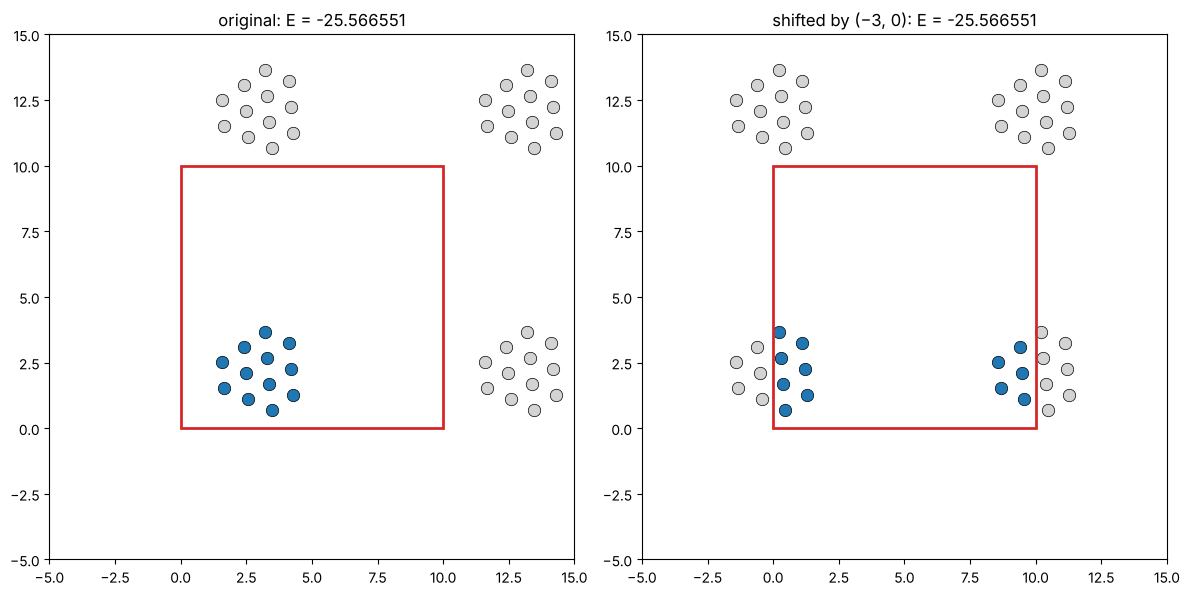

In [3]:
box = np.array([10.0, 10.0])
periodic = LennardJones(eps0=1.0, box=box)
pos = np.array([[4.112, 3.231], [1.579, 2.513], [2.567, 1.101], [2.395, 3.083],
                [2.482, 2.092], [3.467, 0.679], [3.381, 1.672], [1.665, 1.521],
                [4.197, 2.241], [3.295, 2.660], [4.284, 1.250], [3.210, 3.653]])


def draw_periodic(ax, pos, box, images=1):
    for i in range(-images, images + 1):
        for j in range(-images, images + 1):
            shifted = pos + np.array([i, j]) * box
            ax.scatter(*shifted.T, s=80, c="C0" if i == j == 0 else "lightgray",
                       edgecolor="black", lw=0.5)
    ax.add_patch(plt.Rectangle((0, 0), *box, fill=False, lw=2, color="C3"))
    ax.set(aspect="equal", xlim=(-5, 15), ylim=(-5, 15))


fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, p, title in [(axes[0], pos, "original"), (axes[1], (pos - [3, 0]) % box, "shifted by (−3, 0)")]:
    draw_periodic(ax, p, box)
    ax.set_title(f"{title}: E = {periodic.energy(p):.6f}")
fig.tight_layout()
plt.show()

## Which 2D crystal is most stable?
Energy per atom of an infinite square and an infinite triangular lattice, as
a function of the nearest-neighbour distance $a$, computed in periodic cells
of 36 atoms.

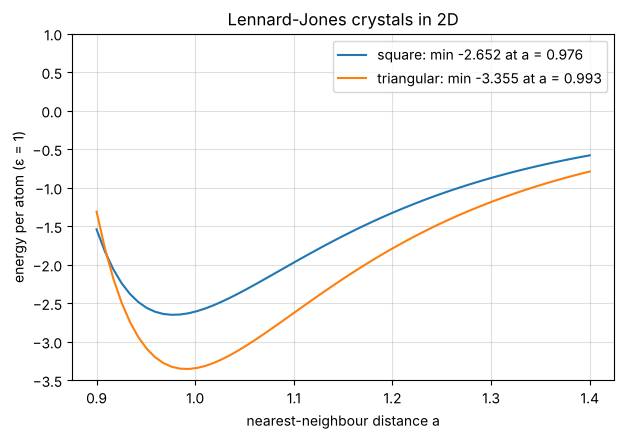

In [4]:
def square_lattice(a, n=6):
    pos = np.array([(i, j) for i in range(n) for j in range(n)], dtype=float) * a
    return pos, np.array([n * a, n * a])


def triangular_lattice(a, n=6):
    pos = np.array([(i + 0.5 * (j % 2), j * np.sqrt(3) / 2) for i in range(n) for j in range(n)]) * a
    return pos, np.array([n * a, n * a * np.sqrt(3) / 2])


lattice_constants = np.linspace(0.9, 1.4, 60)
fig, ax = plt.subplots(figsize=(7, 4.5))
for make, name in [(square_lattice, "square"), (triangular_lattice, "triangular")]:
    e = []
    for a in lattice_constants:
        p, cell = make(a)
        e.append(LennardJones(eps0=1.0, box=cell).energy(p) / len(p))
    e = np.array(e)
    ax.plot(lattice_constants, e, label=f"{name}: min {e.min():.3f} at a = {lattice_constants[e.argmin()]:.3f}")
ax.set(xlabel="nearest-neighbour distance a", ylabel="energy per atom (ε = 1)",
       ylim=(-3.5, 1), title="Lennard-Jones crystals in 2D")
ax.grid(True, alpha=0.4)
ax.legend()
plt.show()

Each atom in the triangular lattice has six nearest neighbours instead of
four, so it is clearly the more stable crystal – matching the triangular
patches seen in the optimised clusters.